# Task 2: Writer identification with a CNN

## Prediction task

- **Input:** one 28 × 28 grayscale image of a digit (0–4). The model is **not** told which digit it is.
- **Response:** the writer ID, one of 20 classes (`person_id` 1–20, coded 0–19 for Keras).
- **Type:** closed-set, multi-class classification. Every test image was written by one of the 20 known writers.

## Data split

| Set | Sessions | Images | Used for |
|---|---|---|---|
| Train | 1, 2, 3 | 15,000 | fitting the weights |
| Validation | 4 | 5,000 | early stopping (choosing the number of epochs) |
| Test | 5 | 5,000 | final evaluation, used once |

Splitting by session means the model is tested on a recording session it has never seen.
This matches the real use case: identifying a known writer from new handwriting, written
on a different occasion. The EDA (notebook 02) showed that images within one session are
near-copies of each other, so a random split would put near-duplicates in both train and
test. Section 7 shows what that does to the results. Task 4 discusses the split in detail.

The model follows the CNN structure from Lecture 4: convolutional layers with 3 × 3 filters and
ReLU, max pooling, dropout, a dense layer, and a softmax output trained with categorical
cross-entropy and Adam.

In [1]:
import sys
sys.path.append("../src")

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # hide TensorFlow start-up messages

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.metrics import confusion_matrix, f1_score

from data_utils import load_handwriting

keras.utils.set_random_seed(42)   # makes results repeatable

images, meta = load_handwriting()          # pixels already scaled to [0, 1]
x = images[..., None]                       # add channel dimension: (25000, 28, 28, 1)
y = meta["person_id"].to_numpy() - 1        # writer IDs 0-19
n_writers = 20

I0000 00:00:1791970463.309486    2060 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791970465.391535    2060 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Split by session

In [2]:
session = meta["session"].to_numpy()
train_idx = np.where(session <= 3)[0]
val_idx = np.where(session == 4)[0]
test_idx = np.where(session == 5)[0]

x_train, x_val, x_test = x[train_idx], x[val_idx], x[test_idx]
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]

# One-hot encode the labels for categorical cross-entropy
y_train_1h = keras.utils.to_categorical(y_train, n_writers)
y_val_1h = keras.utils.to_categorical(y_val, n_writers)

print("train:", x_train.shape, "| validation:", x_val.shape, "| test:", x_test.shape)

train: (15000, 28, 28, 1) | validation: (5000, 28, 28, 1) | test: (5000, 28, 28, 1)


## 2. Define the CNN

In [3]:
def build_cnn(augment=False, n_classes=20, dropout=0.25, dense_units=128):
    model_layers = [keras.Input(shape=(28, 28, 1))]
    if augment:
        # Small random changes to each training image, applied only during training.
        # They mimic how a writer's digits move between sessions (position, size, tilt).
        model_layers += [
            layers.RandomRotation(0.04),             # up to about +/-15 degrees
            layers.RandomZoom(0.1),                  # up to 10% bigger or smaller
            layers.RandomTranslation(0.1, 0.1),      # up to 10% shift up/down/left/right
        ]
    model_layers += [
        layers.Conv2D(32, kernel_size=3, activation="relu"),   # 26 x 26 x 32
        layers.Conv2D(32, kernel_size=3, activation="relu"),   # 24 x 24 x 32
        layers.MaxPooling2D(pool_size=2),                      # 12 x 12 x 32
        layers.Dropout(dropout),
        layers.Conv2D(64, kernel_size=3, activation="relu"),   # 10 x 10 x 64
        layers.MaxPooling2D(pool_size=2),                      # 5 x 5 x 64
        layers.Dropout(dropout),
        layers.Flatten(),                                      # 1600
        layers.Dense(dense_units, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(n_classes, activation="softmax"),         # one probability per writer
    ]
    model = keras.Sequential(model_layers)
    model.compile(optimizer="adam",
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])
    return model

build_cnn().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 10, 10, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,572 (920.20 KB)

 Trainable params: 235,572 (920.20 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Train with early stopping

Training stops when the validation loss has not improved for 5 epochs, and the weights
from the best epoch are kept. Two versions are trained:

- **Baseline:** the CNN as defined above.
- **Augmented:** the same CNN with random rotation, zoom and shift applied to training images
  (Lecture 4, data augmentation). Validation and test images are never altered.

In [4]:
def train(model, verbose=2):
    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                               restore_best_weights=True)
    history = model.fit(x_train, y_train_1h,
                        validation_data=(x_val, y_val_1h),
                        epochs=40, batch_size=128,
                        callbacks=[early_stop], verbose=verbose)
    return pd.DataFrame(history.history).set_axis(
        range(1, len(history.history["loss"]) + 1))

keras.utils.set_random_seed(42)
baseline = build_cnn(augment=False)
hist_baseline = train(baseline)

Epoch 1/40


118/118 - 11s - 95ms/step - accuracy: 0.3737 - loss: 1.9382 - val_accuracy: 0.5838 - val_loss: 1.4573


Epoch 2/40


118/118 - 8s - 71ms/step - accuracy: 0.7587 - loss: 0.6872 - val_accuracy: 0.5826 - val_loss: 1.6044


Epoch 3/40


...

118/118 - 9s - 80ms/step - accuracy: 0.9071 - loss: 0.2548 - val_accuracy: 0.5578 - val_loss: 2.4373


Epoch 5/40


118/118 - 9s - 72ms/step - accuracy: 0.9299 - loss: 0.1908 - val_accuracy: 0.5804 - val_loss: 2.5308


Epoch 6/40


118/118 - 9s - 78ms/step - accuracy: 0.9422 - loss: 0.1590 - val_accuracy: 0.5728 - val_loss: 2.7155


In [5]:
keras.utils.set_random_seed(42)
model = build_cnn(augment=True)
hist_aug = train(model)

Epoch 1/40


118/118 - 13s - 113ms/step - accuracy: 0.1377 - loss: 2.7400 - val_accuracy: 0.3504 - val_loss: 2.0871


Epoch 2/40


118/118 - 10s - 83ms/step - accuracy: 0.2614 - loss: 2.2456 - val_accuracy: 0.4800 - val_loss: 1.4702


Epoch 3/40


...

118/118 - 11s - 90ms/step - accuracy: 0.5601 - loss: 1.2241 - val_accuracy: 0.5706 - val_loss: 1.1425


Epoch 12/40


118/118 - 10s - 82ms/step - accuracy: 0.5688 - loss: 1.1952 - val_accuracy: 0.5378 - val_loss: 1.3130


Epoch 13/40


118/118 - 11s - 91ms/step - accuracy: 0.5723 - loss: 1.1706 - val_accuracy: 0.5698 - val_loss: 1.2169


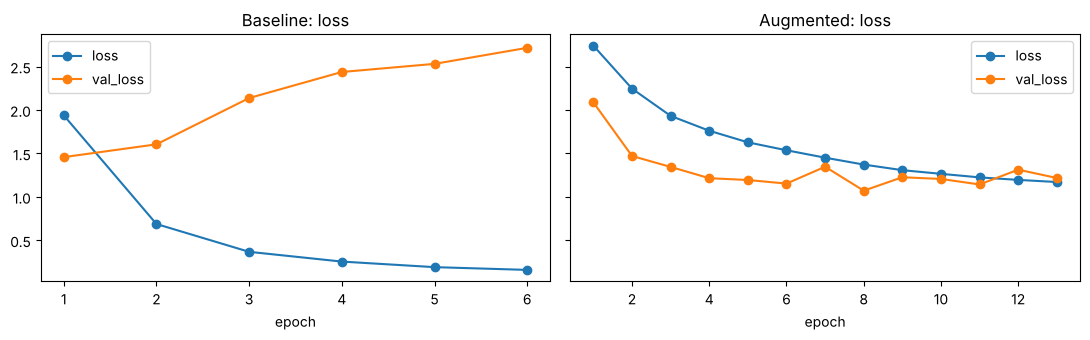

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, (name, hist) in zip(axes, [("Baseline", hist_baseline), ("Augmented", hist_aug)]):
    hist[["loss", "val_loss"]].plot(ax=ax, marker="o")
    ax.set_title(f"{name}: loss")
    ax.set_xlabel("epoch")
plt.tight_layout()
plt.show()

In [7]:
def test_accuracy(m):
    return (m.predict(x_test, verbose=0).argmax(axis=1) == y_test).mean()

print(f"Baseline test accuracy:  {test_accuracy(baseline):.3f}")
print(f"Augmented test accuracy: {test_accuracy(model):.3f}")

Baseline test accuracy:  0.564


Augmented test accuracy: 0.635


The remaining sections evaluate the **augmented** model.

## 4. Overall performance on the test session (session 5)

In [8]:
probs = model.predict(x_test, verbose=0)    # (5000, 20) probabilities
pred = probs.argmax(axis=1)

accuracy = (pred == y_test).mean()

# Top-3: is the true writer among the 3 most likely writers?
top3 = np.argsort(probs, axis=1)[:, -3:]
top3_accuracy = np.mean([y_test[i] in top3[i] for i in range(len(y_test))])

macro_f1 = f1_score(y_test, pred, average="macro")

print(f"Accuracy (top-1):  {accuracy:.3f}   (random guessing: {1/n_writers:.3f})")
print(f"Top-3 accuracy:    {top3_accuracy:.3f}")
print(f"Macro F1:          {macro_f1:.3f}")

Accuracy (top-1):  0.635   (random guessing: 0.050)
Top-3 accuracy:    0.905
Macro F1:          0.613


## 5. Performance by digit

       accuracy  top-3 accuracy  baseline accuracy
digit                                             
0         0.702           0.950              0.568
1         0.513           0.868              0.618
2         0.673           0.933              0.456
3         0.666           0.869              0.616
4         0.623           0.905              0.560


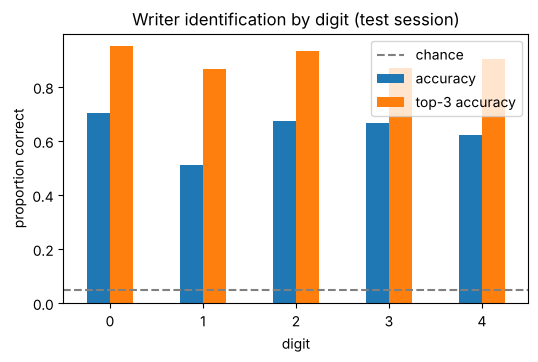

In [9]:
test_meta = meta.iloc[test_idx].reset_index(drop=True)
test_meta["correct"] = pred == y_test
test_meta["top3_correct"] = [y_test[i] in top3[i] for i in range(len(y_test))]

by_digit = test_meta.groupby("digit")[["correct", "top3_correct"]].mean()
by_digit.columns = ["accuracy", "top-3 accuracy"]

# Same table for the baseline, to check whether the digit ranking depends on the model
baseline_correct = baseline.predict(x_test, verbose=0).argmax(axis=1) == y_test
by_digit["baseline accuracy"] = pd.Series(baseline_correct).groupby(test_meta["digit"]).mean()
print(by_digit.round(3))
by_digit = by_digit[["accuracy", "top-3 accuracy"]]

by_digit.plot.bar(figsize=(6, 3.5), rot=0)
plt.axhline(1 / n_writers, color="grey", linestyle="--", label="chance")
plt.ylabel("proportion correct")
plt.title("Writer identification by digit (test session)")
plt.legend()
plt.show()

## 6. Performance by writer, and which writers get confused

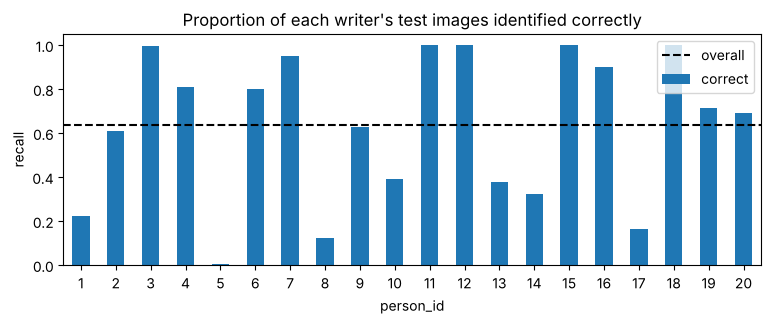

In [10]:
by_writer = test_meta.groupby("person_id")["correct"].mean()
by_writer.plot.bar(figsize=(9, 3), rot=0)
plt.axhline(accuracy, color="black", linestyle="--", label="overall")
plt.ylabel("recall")
plt.title("Proportion of each writer's test images identified correctly")
plt.legend()
plt.show()

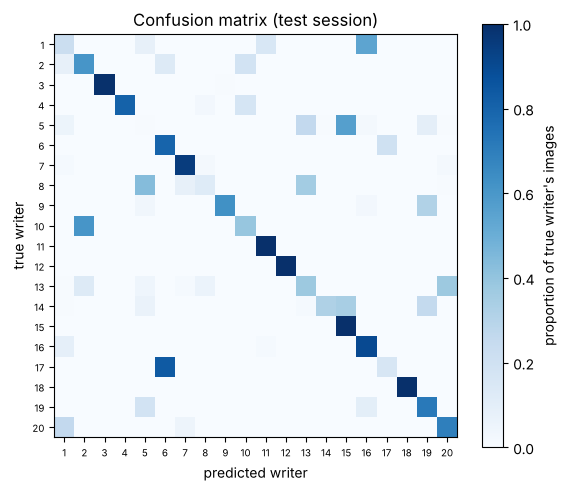

writer 17 predicted as writer 6: 0.84
writer 10 predicted as writer 2: 0.61
writer 5 predicted as writer 15: 0.56
writer 1 predicted as writer 16: 0.54
writer 8 predicted as writer 5: 0.44


In [11]:
cm = confusion_matrix(y_test, pred, normalize="true")   # rows sum to 1

plt.figure(figsize=(6.5, 5.5))
plt.imshow(cm, cmap="Blues")
plt.colorbar(label="proportion of true writer's images")
plt.xticks(range(n_writers), range(1, n_writers + 1), fontsize=7)
plt.yticks(range(n_writers), range(1, n_writers + 1), fontsize=7)
plt.xlabel("predicted writer")
plt.ylabel("true writer")
plt.title("Confusion matrix (test session)")
plt.show()

# Most common mistakes
off_diag = [(cm[i, j], i + 1, j + 1) for i in range(n_writers)
            for j in range(n_writers) if i != j]
for share, true_w, pred_w in sorted(off_diag, reverse=True)[:5]:
    print(f"writer {true_w} predicted as writer {pred_w}: {share:.2f}")

## 6b. Using several images from the same writer

In practice a document contains more than one character. Here we average the predicted
probabilities over *k* randomly chosen test images from the same writer, then pick the
most likely writer.

In [12]:
rng = np.random.default_rng(0)
results = []
for k in [1, 2, 3, 5, 10]:
    hits = []
    for writer in range(n_writers):
        writer_rows = np.where(y_test == writer)[0]
        for _ in range(200):
            chosen = rng.choice(writer_rows, size=k, replace=False)
            hits.append(probs[chosen].mean(axis=0).argmax() == writer)
    results.append({"images per decision": k, "accuracy": np.mean(hits)})

multi = pd.DataFrame(results).set_index("images per decision")
print(multi.round(3))

                     accuracy
images per decision          
1                       0.631
2                       0.683
3                       0.698
5                       0.712
10                      0.724


## 7. Comparison: random split (ignores sessions)

Same baseline model, but images are split at random (60% train, 20% validation, 20% test), so the
test set contains images from sessions the model trained on. Epochs are capped at 15 to
keep the run short.

In [13]:
keras.utils.set_random_seed(42)
shuffled = np.random.default_rng(0).permutation(len(x))
n = len(x)
r_train, r_val, r_test = (shuffled[:int(0.6 * n)],
                          shuffled[int(0.6 * n):int(0.8 * n)],
                          shuffled[int(0.8 * n):])

random_model = build_cnn(augment=False)
random_model.fit(x[r_train], keras.utils.to_categorical(y[r_train], n_writers),
                 validation_data=(x[r_val], keras.utils.to_categorical(y[r_val], n_writers)),
                 epochs=15, batch_size=128, verbose=0,
                 callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])

random_pred = random_model.predict(x[r_test], verbose=0).argmax(axis=1)
random_accuracy = (random_pred == y[r_test]).mean()

print(f"Test accuracy, split by session (baseline): {test_accuracy(baseline):.3f}")
print(f"Test accuracy, random split (baseline):     {random_accuracy:.3f}")

Test accuracy, split by session (baseline): 0.564
Test accuracy, random split (baseline):     0.999


## Notes for the report

Write these up in your own words:

- **Overall accuracy:** out of 20 known writers, how often a single new digit image is
  attributed to the right person. Compare with chance (0.05) and with the random split.
- **Top-3 accuracy:** how often the true writer is on a 3-person shortlist, e.g. for a human
  examiner to check.
- **Macro F1 and per-writer recall:** whether some writers are much harder to identify,
  which an overall average can hide.
- **By digit:** which digits carry more writer information, and possible reasons from the EDA.
  Note whether the ranking is the same for the baseline and augmented models. If it is not,
  differences between digits may be small relative to run-to-run variation.
- **Augmentation:** why random shifts, zooms and rotations help on a new session.
- **Several images:** how accuracy changes when a decision uses more handwriting.
- **Limits:** a closed set of 20 writers, one test session (session 5), and results from a
  single training run. An unknown writer would still be assigned to one of the 20.